In [188]:
import  pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


In [189]:
df = pd.read_csv('/content/WA_Fn-UseC_-Telco-Customer-Churn 2.ipynb')
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [190]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [191]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [192]:
# Нет Nan в dataframe
df.isna().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


<Figure size 800x1000 with 0 Axes>

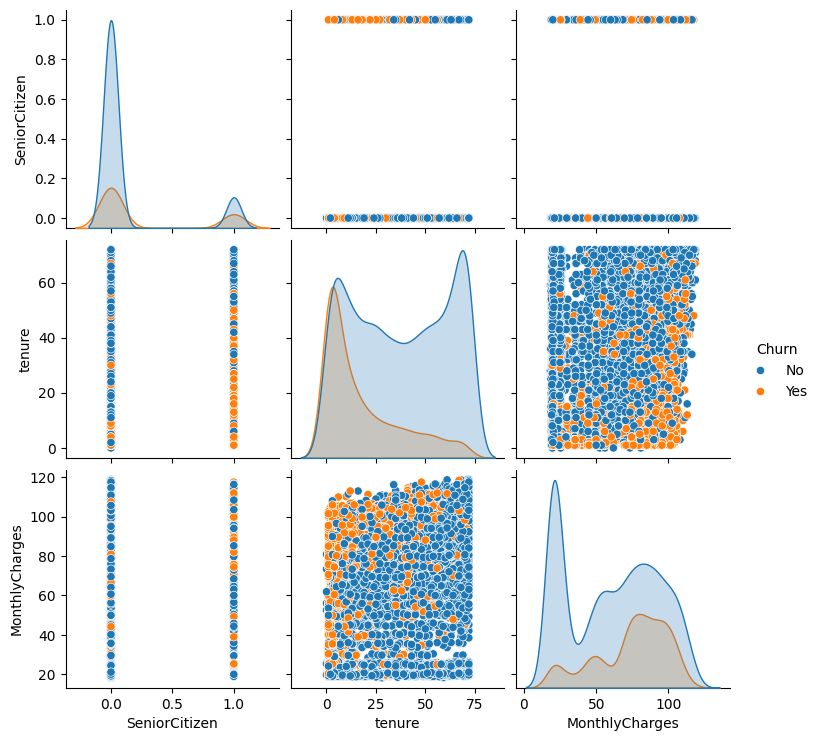

In [193]:
plt.figure(figsize=(8,10),dpi=100)
sns.pairplot(df,hue = 'Churn')

<Axes: xlabel='tenure', ylabel='TotalCharges'>

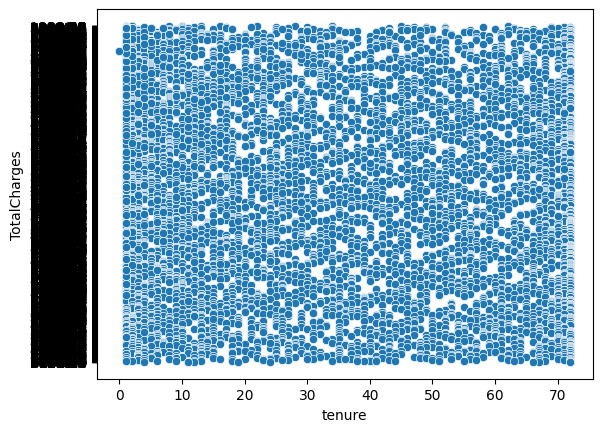

In [194]:
# 37% "Yes" and 63% "NO"
df['Churn'].value_counts()
sns.scatterplot(x = df['tenure'],y= df['TotalCharges'])



<Axes: ylabel='TotalCharges'>

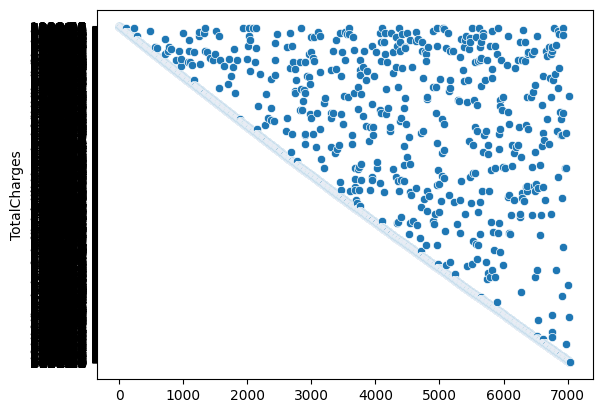

In [195]:
#df['Month_count'] = df['TotalCharges'].apply(lambda x: x.int())//df['MonthlyCharges'].apply(int)
sns.scatterplot(df['TotalCharges'])


In [196]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'],errors='coerce')
df['TotalCharges'] = df['TotalCharges'].fillna(np.median(df['TotalCharges'][df['TotalCharges'].isna()==False]))

<Axes: >

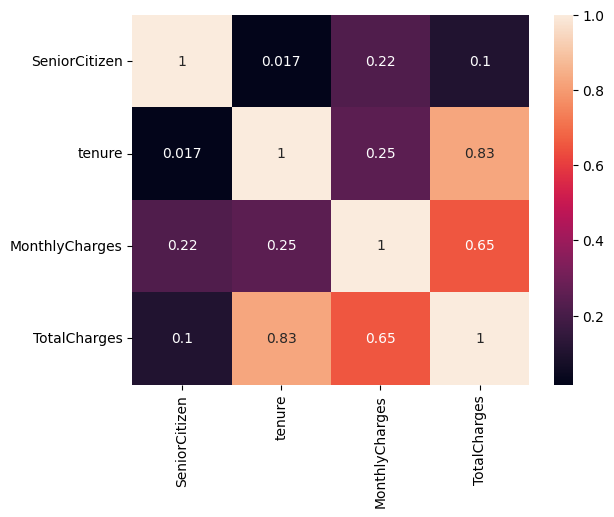

In [197]:
#tenure вообще не коррелирует с SeniorCitizen
sns.heatmap(df.corr(numeric_only=True),annot= True)

<Axes: ylabel='TotalCharges'>

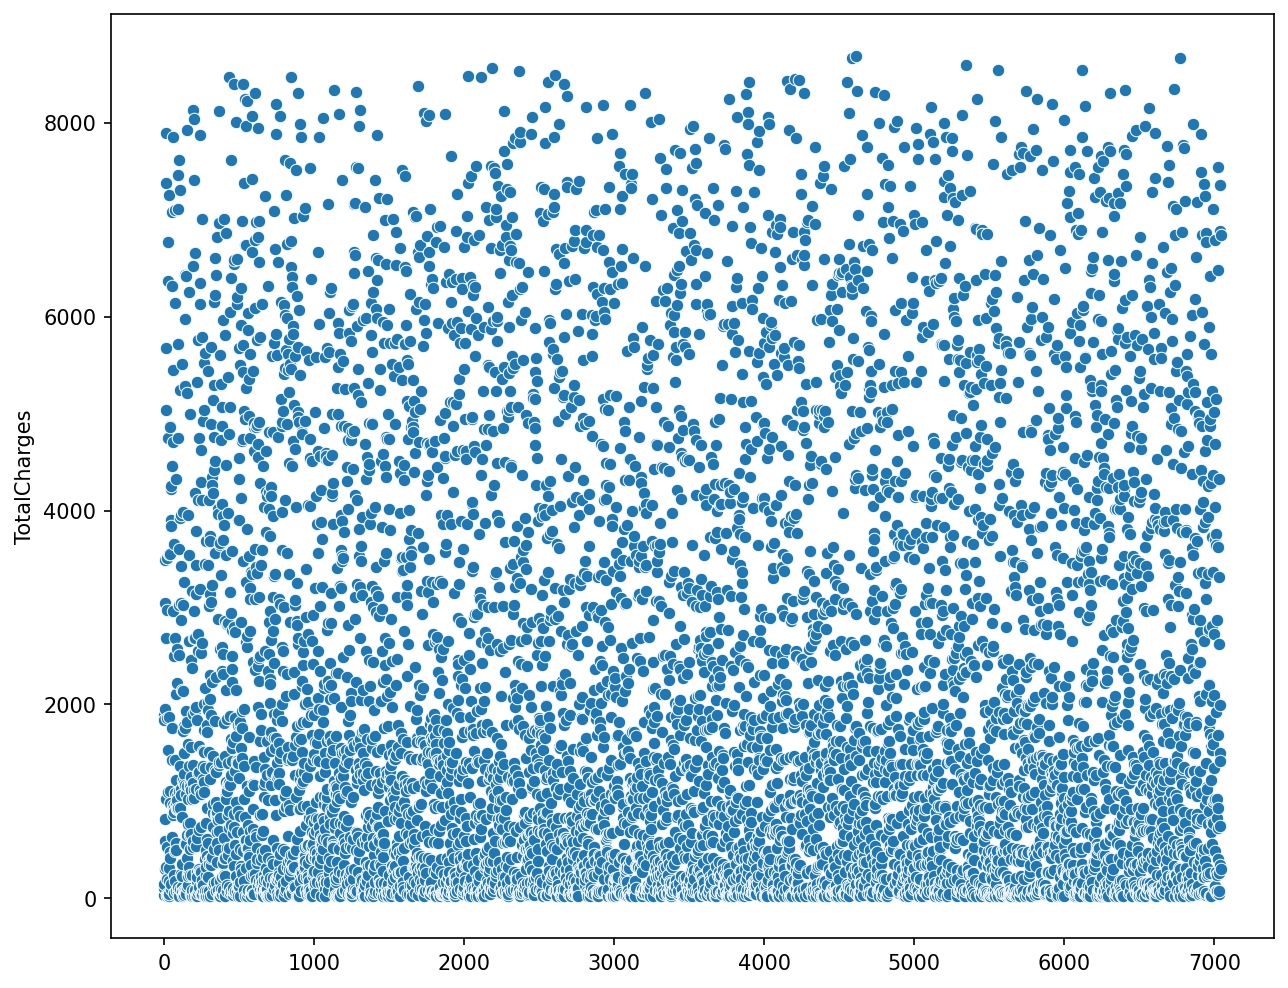

In [198]:
plt.figure(figsize=(10,8),dpi = 150)
sns.scatterplot(df['TotalCharges'])

<Axes: ylabel='MonthlyCharges'>

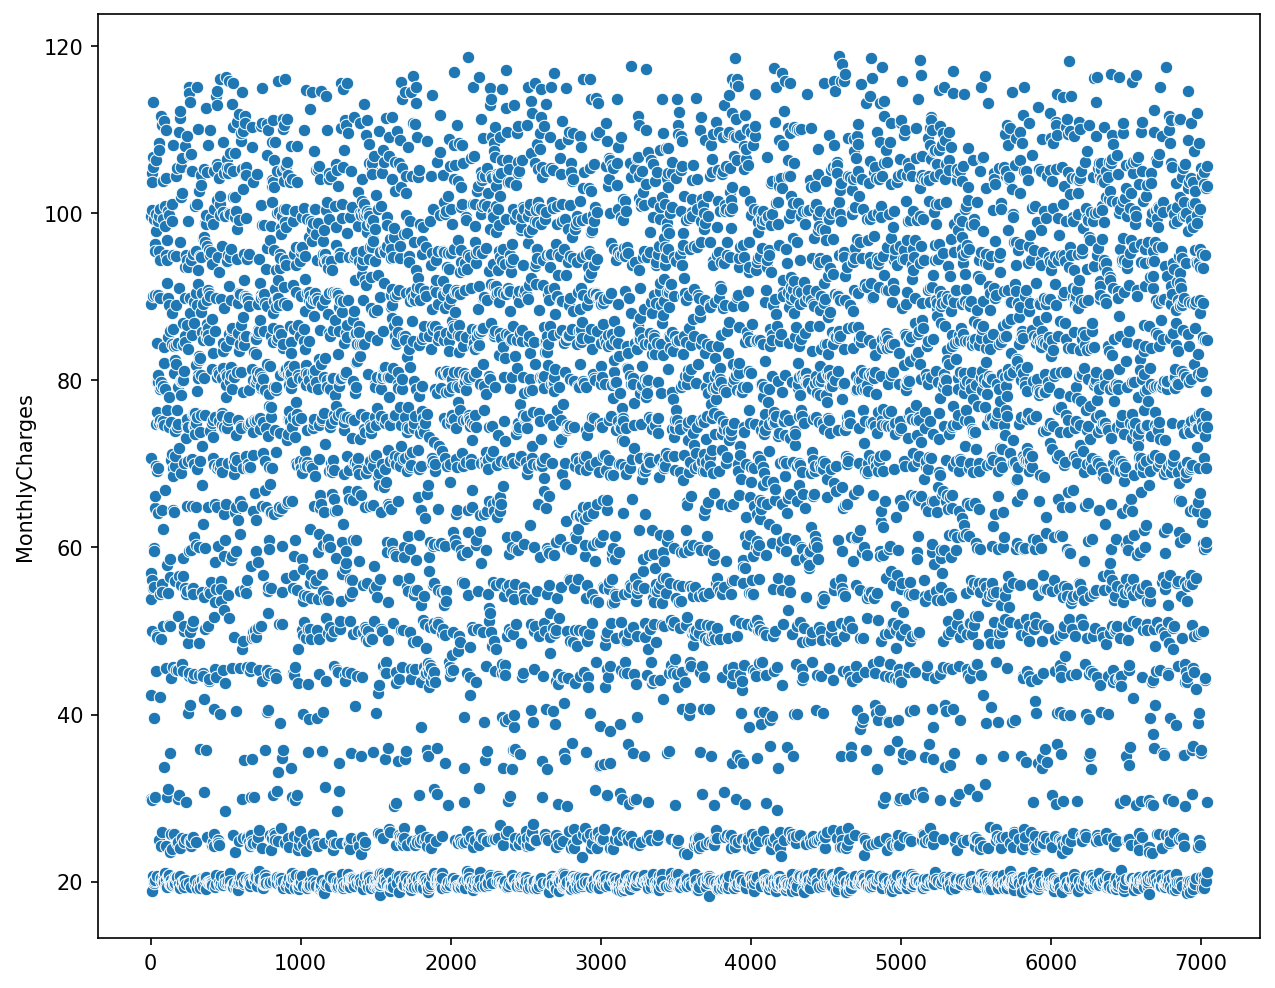

In [199]:
plt.figure(figsize=(10,8),dpi = 150)
sns.scatterplot(df['MonthlyCharges'])

<Axes: ylabel='tenure'>

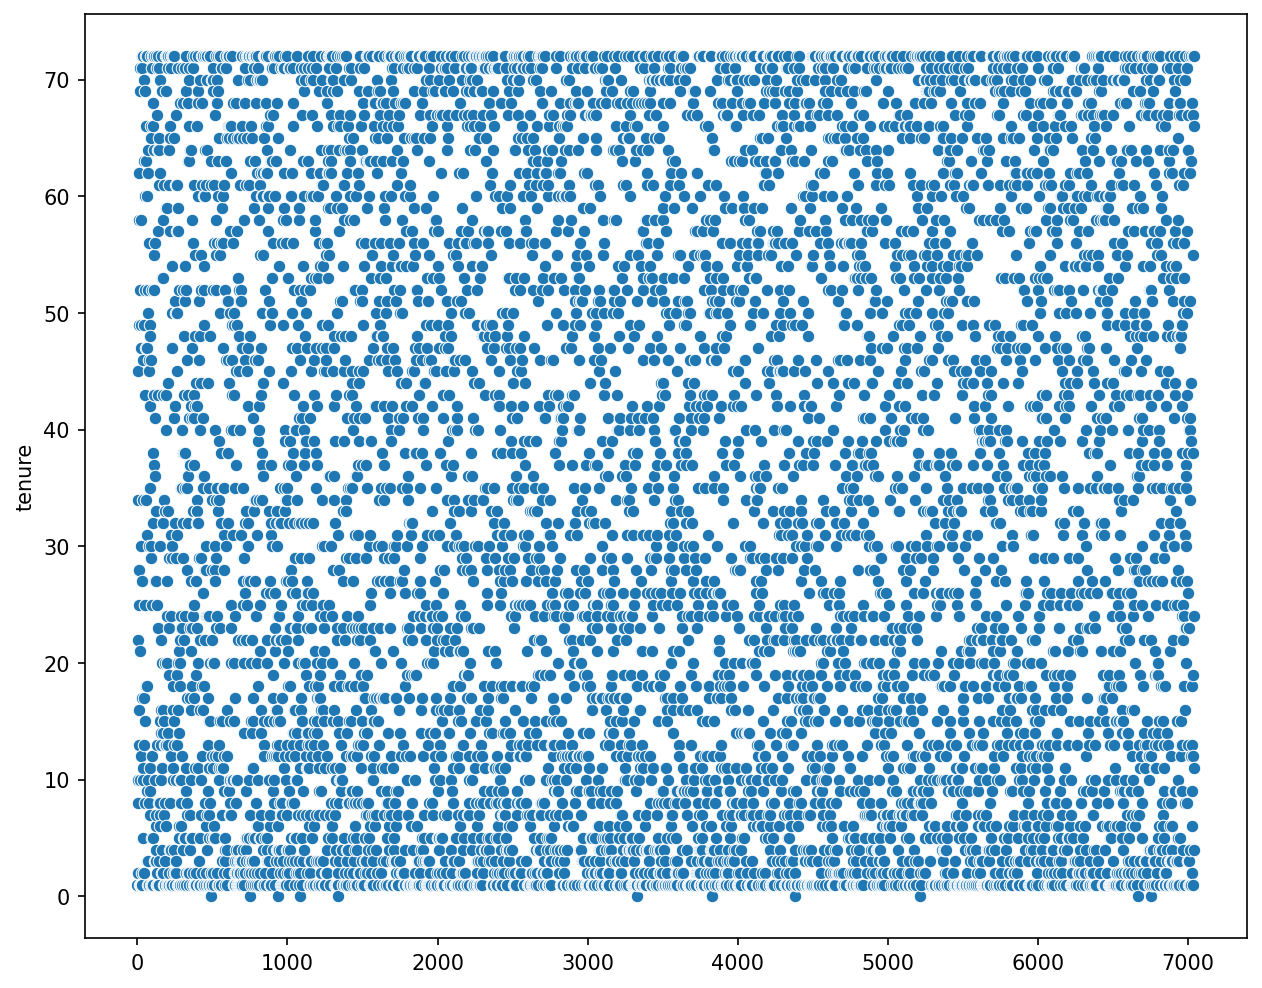

In [200]:
plt.figure(figsize=(10,8),dpi = 150)
sns.scatterplot(df['tenure'])



In [201]:
df['tenure_group'] = pd.cut(df['tenure'],bins=[0,12,24,48,72])

In [206]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier,GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split,GridSearchCV,cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, classification_report,roc_auc_score,accuracy_score,f1_score,precision_score,recall_score
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE

In [203]:
X = pd.get_dummies(df.drop(df[['Churn','customerID']],axis=1),drop_first=True)
#X = df.drop(['Churn','customerID'],axis=1)
y = df['Churn']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=47)#,stratify=y)

In [204]:
model = LogisticRegression(penalty='l2')
scaler = StandardScaler()
X_train_S = scaler.fit_transform(X_train)
X_test_S = scaler.fit(X_test)
model.fit(X_train_S,y_train)
#param_grid = {'penalty':['l1','l2']}
#G = GridSearchCV(model,param_grid)
model.fit(X_train_S,y_train)
y_pred = model.predict(X_test)
print(confusion_matrix(y_test,y_pred))
print(classification_report(y_test,y_pred))
#print(roc_auc_score(y_test,y_pred))
#G.best_params_






[[  69 1221]
 [  97  374]]
              precision    recall  f1-score   support

          No       0.42      0.05      0.09      1290
         Yes       0.23      0.79      0.36       471

    accuracy                           0.25      1761
   macro avg       0.33      0.42      0.23      1761
weighted avg       0.37      0.25      0.17      1761



/usr/local/lib/python3.12/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


In [207]:
pipe = Pipeline([('smote', SMOTE(random_state=42)),('classifier',GradientBoostingClassifier(random_state=42,n_estimators=150))])
param_grid = {'classifier__n_estimators':[32,64,100,128,150]}
G_g = GridSearchCV(pipe,param_grid)
G_g.fit(X_train,y_train)
y_pred_g = G_g.predict(X_test)
y_proba = G_g.predict_proba(X_test)[:,1]
G_g.best_params_

{'classifier__n_estimators': 128}

In [208]:
print(confusion_matrix(y_test,y_pred_g))
print(classification_report(y_test,y_pred_g))
print(roc_auc_score(y_test,y_proba))
#print(recall_score(y_test,y_proba))
print(accuracy_score(y_test,y_pred_g))
#print(f1_score(y_test,y_pred))
#print(precision_score(y_test,y_pred))
print(y_test.value_counts())
print(y_train.value_counts())



[[1074  216]
 [ 162  309]]
              precision    recall  f1-score   support

          No       0.87      0.83      0.85      1290
         Yes       0.59      0.66      0.62       471

    accuracy                           0.79      1761
   macro avg       0.73      0.74      0.74      1761
weighted avg       0.79      0.79      0.79      1761

0.833976859395316
0.7853492333901193
Churn
No     1290
Yes     471
Name: count, dtype: int64
Churn
No     3884
Yes    1398
Name: count, dtype: int64


In [ ]:
#l = [1,5,15,50]
#for i in l:
#  model_k = KNeighborsClassifier(n_neighbors=i)
 # scaler = StandardScaler()
  #X_train_scaler = scaler.fit_transform(X_train)
  #X_test_scaler = scaler.transform(X_test)
  #model_k.fit(X_train_scaler,y_train)
 # y_predK = model_k.predict(X_test)
  #print(i)
  #print(confusion_matrix(y_test,y_predK))
  #print(classification_report(y_test,y_predK))

In [ ]:
#model_k = KNeighborsClassifier()
#scaler = StandardScaler()
#X_train_scaler = scaler.fit_transform(X_train)
#X_test_scaler = scaler.transform(X_test)
#param_grid_K = {'n_neighbors':[1,5,15,50]}
#G_K = GridSearchCV(model_k,param_grid_K)
#G_K.fit(X_train_scaler,y_train)
#y_predK = G_K.predict(X_test_scaler)
#print(confusion_matrix(y_test,y_predK))
#print(classification_report(y_test,y_predK))

In [ ]:
#model_f = RandomForestClassifier()#max_depth= 15, min_samples_split= 5, n_estimators= 64)
#param_grid_f = {'n_estimators':[64,100,128],
 #             'min_samples_split':[2,3,5,8],
  #            'max_depth':[12,15]}
#G_f = GridSearchCV(model_f,param_grid_f)
#G_f.fit(X_train,y_train)
#model_f.fit(X_train,y_train)
#y_pred_f = G_f.predict(X_test)
#G_f.best_params_

In [ ]:
#print(confusion_matrix(y_test,y_pred_f))
#print(classification_report(y_test,y_pred_f))
#print(roc_auc_score(y_test,y_pred_f))
#pd.DataFrame(model_f.feature_importances_,X.columns)

In [1]:
df.info()

NameError: name 'df' is not defined